# From ratios to metres: reconstructing the absolute pattern of a blast and checking it against the paper

**Level 2: The method in practice** · Needs: 01-the-data/01-the-corpus-and-the-cases · Reading time: about 20 minutes

## Objectives

The classical mean-size equation needs a rock volume and an explosive mass in metres and kilograms, but the published corpus gives only dimensionless ratios. This notebook shows how the engine recovers the absolute pattern, how it proves the recovery against the paper's own prose, and what it does when nothing fixes the scale.

By the end you will have:

- rebuilt one reconstructed pattern by hand and matched the engine's `reconstruct_pattern`;
- run the reconstruction check against all the dimensional statements the source prose makes;
- seen the check fail when the hole diameter is wrong, which is what gives it power;
- seen the one site that the engine refuses to reconstruct, and the committed artifact that records the refusal.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus and the site narratives (hole diameters, bench heights, burdens) | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the table and the `SITE_GEOMETRY` registry inside the `blastfrag` wheel |
| The geometry negative control | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-miami/case.json` |

Each registry entry stores the hole diameter of a site, **how it was obtained** (quoted from the paper, derived from a stated bench height, or chosen), and the dimensional statements the paper makes about that site, as ranges in metres.

## Method

The ratios of a blast are defined against its burden `B` and its hole diameter `D`, so one known length (the diameter) fixes every other length:

- burden `B = (B/D) * D`
- spacing `S = (S/B) * B`
- bench height `H = (H/B) * B`
- stemming `T = (T/B) * B`

The rock volume per hole is `V = B * S * H` and the explosive mass is `Q = Pf * V`, with `Pf` the powder factor the corpus prints directly (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957). The hole diameter is the only quantity that cannot be computed from the table, so it is read from the prose of each site and stored in the registry.

### Step 1: the registry

The cell prints, for every site, the diameter and the first words of the sentence that gives its source. Three kinds of source appear: a diameter quoted from the paper, a diameter derived from a stated bench height (flagged `DERIVED`), and no diameter at all (flagged `NOT PUBLISHED`).

In [2]:
# Imports, then the registry of site geometry shipped with the engine
import dataclasses
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
sites = sorted({b.site for b in train})
print(f"{'site':<14}{'D (mm)':>8}  source of the diameter")
for site in sites:
    geometry = bf.SITE_GEOMETRY[site]
    diameter = "-" if geometry.hole_diameter_mm is None else f"{geometry.hole_diameter_mm:g}"
    print(f"{site:<14}{diameter:>8}  {geometry.diameter_source[:70]}")

site            D (mm)  source of the diameter
Akdaglar            89  "The drillhole diameter is 89 mm"
Dongri-Buzurg      100  "The hole diameter was 100 mm and bench height was 6 to 11 m"
Enusa              165  "Hole diameters for the Enusa and Reocin mines were 165 and 229 mm"
Miami                -  NOT PUBLISHED and not derivable. The paper gives no diameter and no ab
Mrica               76  "The hole diameter was 76 mm and bench height was 10 to 15 m"
Murgul             165  "The drillhole diameter applied was 165 mm"
Ozmert              89  "The hole diameter is 89 mm"
Reocin             229  "Hole diameters for the Enusa and Reocin mines were 165 and 229 mm"
Reocin-UG         91.2  DERIVED, not published. The paper states an 18 m bench for the Reocin 
Soma               210  "The diameter of the blast holes was 21 cm"


### Step 2: one blast by hand

The cell applies the four formulas above to blast `En1` (Enusa, hole diameter 165 mm) with plain arithmetic, then asks the engine for the same pattern and compares the two. The engine call is `reconstruct_pattern`; the hand calculation exists only to show there is no hidden step.

In [3]:
# Reconstruct En1 by hand and with the engine
blast = next(b for b in train if b.blast_id == "En1")
diameter_m = bf.SITE_GEOMETRY[blast.site].hole_diameter_mm / 1000.0
burden = blast.B_over_D * diameter_m
by_hand = {
    "burden_m": burden,
    "spacing_m": blast.S_over_B * burden,
    "bench_height_m": blast.H_over_B * burden,
    "stemming_m": blast.T_over_B * burden,
}
pattern = bf.reconstruct_pattern(blast)
for name, value in by_hand.items():
    print(f"{name:<15} hand {value:8.4f}   engine {getattr(pattern, name):8.4f}   equal: {value == getattr(pattern, name)}")
print(f"rock volume per hole V = {pattern.rock_volume_m3:.2f} m3")
print(f"explosive mass per hole Q = {pattern.charge_mass_kg:.2f} kg  (Pf = {pattern.powder_factor_kg_m3} kg/m3)")

burden_m        hand   4.4996   engine   4.4996   equal: True
spacing_m       hand   5.5794   engine   5.5794   equal: True
bench_height_m  hand   5.9844   engine   5.9844   equal: True
stemming_m      hand   3.5096   engine   3.5096   equal: True
rock volume per hole V = 150.24 m3
explosive mass per hole Q = 72.11 kg  (Pf = 0.48 kg/m3)


### Step 3: prove the reconstruction against the paper

If the diameter were wrong, every length would be wrong by the same factor. The paper's prose states a few lengths directly (for example "the bench height was 6 m"). `verify_reconstruction` reconstructs every blast of a site and requires each stated range to contain the reconstructed range, allowing only the slack that the two-decimal printing of the ratios produces. It raises an `AssertionError` on any violation, so it works as a gate.

In [4]:
# Run the check on the whole corpus and list every dimensional constraint it tested
report = bf.verify_reconstruction(train)
rows = []
for site, entry in report.items():
    for check in entry["checks"]:
        rows.append((site, check))
print(f"{'site':<14}{'quantity':<16}{'paper states (m)':>22}{'reconstructed (m)':>24}  ok")
for site, check in rows:
    stated = f"{check['stated'][0]:g} - {check['stated'][1]:g}"
    got = f"{check['reconstructed'][0]:g} - {check['reconstructed'][1]:g}"
    print(f"{site:<14}{check['quantity']:<16}{stated:>22}{got:>24}  {check['ok']}")
print("constraints tested:", len(rows), "| satisfied:", sum(c["ok"] for _, c in rows))

site          quantity              paper states (m)       reconstructed (m)  ok
Akdaglar      burden_m                     1.5 - 2.6               1.6 - 2.5  True
Dongri-Buzurg bench_height_m                  6 - 11                  6 - 11  True
Dongri-Buzurg burden_m                       2 - 2.5                 2 - 2.5  True
Dongri-Buzurg spacing_m                    1.8 - 3.5               2.5 - 3.5  True
Enusa         bench_height_m                   6 - 6           5.984 - 5.984  True
Mrica         bench_height_m                 10 - 15         14.998 - 14.999  True
Murgul        bench_height_m              12 - 12.05         11.999 - 12.014  True
Murgul        burden_m                       4.5 - 5                 4.5 - 5  True
Murgul        spacing_m                    4.5 - 5.5             4.5 - 5.499  True
Ozmert        burden_m                         2 - 3                   2 - 3  True
Ozmert        spacing_m                      2.5 - 3                 2.5 - 3  True
Reocin

### Step 4: does the check have power?

A check that cannot fail proves nothing. The Soma narrative is the useful test: a competing reading of the paper has a 175 mm hole. The cell replaces the Soma diameter in the registry with other values, runs the same check, and restores the original in a `finally` block so nothing leaks into later cells.

In [5]:
# Try wrong diameters for Soma; the registry is restored afterwards
soma = [b for b in train if b.site == "Soma"]
original = bf.SITE_GEOMETRY["Soma"]
outcome = {}
try:
    for diameter in (175.0, 190.0, original.hole_diameter_mm, 230.0):
        bf.SITE_GEOMETRY["Soma"] = dataclasses.replace(original, hole_diameter_mm=diameter)
        try:
            bf.verify_reconstruction(soma)
            outcome[diameter] = "passes"
        except AssertionError:
            outcome[diameter] = "fails"
finally:
    bf.SITE_GEOMETRY["Soma"] = original
for diameter, verdict in outcome.items():
    print(f"D = {diameter:g} mm: {verdict}")

D = 175 mm: fails
D = 190 mm: fails
D = 210 mm: passes
D = 230 mm: fails


### Step 5: where nothing fixes the scale

Miami publishes no hole diameter and no absolute length, so no honest reconstruction exists. The engine raises `GeometryUnavailable` rather than guessing, and `has_absolute_geometry` is the predicate every arm that needs a volume uses to decide whether to answer. The cell counts the blasts that pass and reads the committed artifact of the Miami case, which carries the same refusal in both languages.

In [6]:
# Count the blasts with a resolvable geometry and read the refusal for Miami
resolvable = [b for b in train if bf.has_absolute_geometry(b)]
print("blasts with absolute geometry:", len(resolvable), "of", len(train))
miami = next(b for b in train if b.site == "Miami")
try:
    bf.reconstruct_pattern(miami)
except bf.GeometryUnavailable as refusal:
    print("engine refusal:", str(refusal)[:110], "...")
artifact = json.loads((DERIVED / "real-miami" / "case.json").read_text(encoding="utf-8"))
print("committed reason (en):", artifact["case"]["reason"]["en"][:110], "...")
print("committed reason (es):", artifact["case"]["reason"]["es"][:110], "...")

blasts with absolute geometry: 91 of 97
engine refusal: Mi1: Miami Mine, Arizona, USA publishes no hole diameter and no absolute dimension, so its scale cannot be fix ...
committed reason (en): Nothing in the source fixes this site's absolute scale: no hole diameter, no bench height, no burden. Every mo ...
committed reason (es): Nada en la fuente fija la escala absoluta de este sitio: sin diámetro de perforación, sin altura de banco, sin ...


The last cell of the method plots the reconstructed burden and bench height of every resolvable blast, coloured by site, so the scale the classical equation will see is visible before it is used.

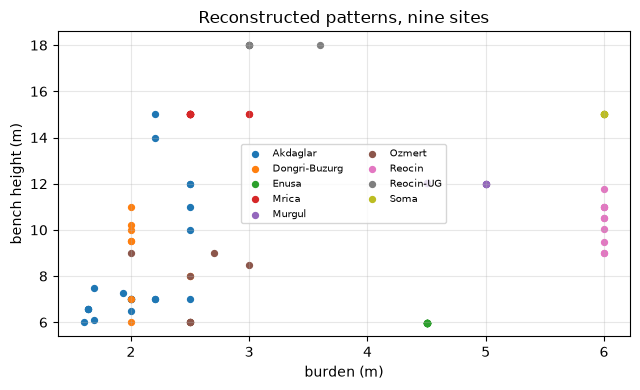

In [7]:
# Burden against bench height in metres, one colour per site
fig, ax = plt.subplots(figsize=(6.5, 4))
for site in sites:
    members = [b for b in resolvable if b.site == site]
    if not members:
        continue
    patterns = [bf.reconstruct_pattern(b) for b in members]
    ax.scatter([p.burden_m for p in patterns], [p.bench_height_m for p in patterns], s=18, label=site)
ax.set_xlabel("burden (m)")
ax.set_ylabel("bench height (m)")
ax.set_title("Reconstructed patterns, nine sites")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Results

**The reconstruction is exact arithmetic on one stored length.** The hand calculation and the engine agree to the last digit on the Enusa blast. The only judgement in the whole recovery is the hole diameter, and the registry records for each site whether it was quoted, derived or absent.

**The check is not a formality.** All 15 dimensional statements the source prose makes are satisfied by the registry, and the Soma test shows the same check failing for 175, 190 and 230 mm and passing only for the registered 210 mm. A wrong diameter cannot hide. What the check cannot do is choose between two readings that both satisfy the prose; the one Soma ambiguity the engine records (which burden the authors intended) is carried as a note of the case, not resolved here.

**The refusal is a result.** 91 of the 97 blasts have a resolvable geometry. The six Miami blasts do not, and the engine, and the committed artifact, say so in both languages instead of returning a number. Every later notebook inherits this: an arm that needs a volume abstains on Miami.

**What this does not show.** Matching the paper's prose proves the lengths are consistent with what the authors wrote, not that the authors measured them correctly, and it says nothing about the accuracy of any prediction made with them.

## Summary

- One stored hole diameter per site turns every ratio into metres; the arithmetic is four multiplications.
- `verify_reconstruction` tests the result against 15 statements of the source prose and fails when the diameter is wrong.
- Where no length is published (Miami) the engine refuses, and 91 of 97 blasts remain usable by the classical arms.
- Next: notebook 03 opens the integrity gate on the corpus itself and the negative control that the refusal feeds (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus, the site narratives and the printed ratios)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/